<a href="https://colab.research.google.com/github/ibrahimelkhalilmehimda/Deep-Learning-projects/blob/main/Plant_disease_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import random
random.seed(0)

import numpy as np
np.random.seed(0)

import tensorflow as tf
tf.random.set_seed(0)

import os
import json
from zipfile import ZipFile
from PIL import Image

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models


In [2]:
!pip install kaggle

In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [4]:
!kaggle datasets download -d abdallahalidev/plantvillage-dataset

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:17<00:00, 123MB/s] 



In [ ]:
!ls

kaggle.json  plantvillage-dataset.zip  sample_data


In [5]:
with ZipFile("plantvillage-dataset.zip", 'r') as zip_ref:
    zip_ref.extractall()

In [ ]:
path ='plantvillage dataset/color'
print(os.listdir("plantvillage dataset"))
print(len(os.listdir(path)))
print(os.listdir(path)[:5])

['grayscale', 'color', 'segmented']
38
['Apple___healthy', 'Tomato___Leaf_Mold', 'Pepper,_bell___healthy', 'Blueberry___healthy', 'Corn_(maize)___Common_rust_']


In [ ]:
print(len(os.listdir("plantvillage dataset/color/Grape___healthy")))
print(os.listdir("plantvillage dataset/color/Grape___healthy")[:5])

423
['94e1829a-d9ce-4638-8c7b-3a67133de4c9___Mt.N.V_HL 6190.JPG', '2b4a92e2-a039-45eb-ad1a-ee9914dfeefe___Mt.N.V_HL 6177.JPG', '0cd6cdbd-1674-4abb-b734-756da4994cd0___Mt.N.V_HL 6052.JPG', '07d28aaf-09ea-4223-9a65-88ef49e54924___Mt.N.V_HL 9121.JPG', '244804b5-05e2-4372-a376-36a0655aff41___Mt.N.V_HL 6121.JPG']


#data processing

(256, 256, 3)


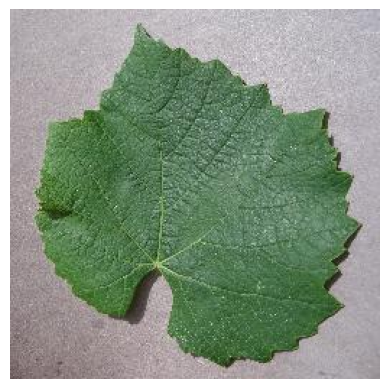

In [ ]:
image_path = '/content/plantvillage dataset/color/Grape___healthy/05cff9d7-0f63-4b6e-9aa3-199cf9ffa64c___Mt.N.V_HL 9111.JPG'

img = mpimg.imread(image_path)

print(img.shape)
plt.imshow(img)
plt.axis('off')
plt.show()


In [ ]:
print(img)

[[[178 172 176]
  [186 180 184]
  [182 176 180]
  ...
  [172 170 181]
  [175 173 184]
  [174 172 183]]

 [[181 175 179]
  [188 182 186]
  [183 177 181]
  ...
  [174 172 183]
  [178 176 187]
  [179 177 188]]

 [[179 173 177]
  [184 178 182]
  [178 172 176]
  ...
  [178 176 187]
  [183 181 192]
  [186 184 195]]

 ...

 [[123 107 108]
  [ 98  82  83]
  [143 127 128]
  ...
  [150 144 148]
  [147 141 145]
  [146 140 144]]

 [[117 101 102]
  [123 107 108]
  [ 96  80  81]
  ...
  [150 144 148]
  [149 143 147]
  [148 142 146]]

 [[107  91  92]
  [ 95  79  80]
  [ 98  82  83]
  ...
  [152 146 150]
  [152 146 150]
  [152 146 150]]]


#the Generator

In [ ]:
batch_size= 32
size=224

In [ ]:
data_gen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

#Train Genarotor

In [ ]:
train_gen = data_gen.flow_from_directory(
    path,
    target_size=(size,size),
    batch_size=batch_size,
    subset='training',
    class_mode='categorical'

)

Found 43456 images belonging to 38 classes.


#Test Genarotor

In [ ]:
test_gen = data_gen.flow_from_directory(
    path,
    target_size=(size,size),
    batch_size=batch_size,
    subset='validation',
    class_mode='categorical'

)

Found 10849 images belonging to 38 classes.


In [ ]:
from tensorflow.keras import Sequential, models, layers
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.models import load_model
from tensorflow.keras.models import Model
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras import optimizers

In [ ]:
convolutional_base = ResNet50(weights='imagenet', include_top=False, input_shape=(256,256,3))
convolutional_base.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 262, 262,  │          0 │ input_layer_2[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 128, 128,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 128, 128,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 128, 128,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 130, 130,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 64, 64,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 64, 64,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 64, 64,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 64, 64,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 64, 64,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 64, 64,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 64, 64,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 64, 64,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 64, 64,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 23,534,592 (89.78 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [ ]:
# Model Definition
model = models.Sequential()

model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(size, size, 3)))
model.add(layers.MaxPooling2D(2, 2))

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D(2, 2))


model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(train_gen.num_classes, activation='softmax'))

In [ ]:
model.compile(optimizer=optimizers.RMSprop(learning_rate=2e-5), loss='categorical_crossentropy', metrics=['acc'])

In [ ]:
history = model.fit(
    train_gen,
    steps_per_epoch=train_gen.samples // batch_size,  # Number of steps per epoch
    epochs=5,  # Number of epochs
    validation_data=test_gen,
    validation_steps=test_gen.samples // batch_size  # Validation steps
)

Epoch 1/5
1092/1358 ━━━━━━━━━━━━━━━━━━━━ 14:36 3s/step - acc: 0.3060 - loss: 2.7118

# model evalution

In [ ]:
val_loss, val_accuracy = model.evaluate(test_gen, steps=test_gen.samples // batch_size)
print(f"Validation Loss: {val_loss}, Validation Accuracy: {val_accuracy}")

In [ ]:
# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

#predictive system

In [ ]:
class_indices = {v: k for k, v in train_gen.class_indices.items()}
def preprocess_image(image_path, size=(224, 224)):
    img = Image.open(image_path)
    img = img.resize(size)
    img_array = np.array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array.astype('float32') / 255.
    return img_array

def predict_image_class(model, image_path, class_indices):
    preprocessed_img = preprocess_image(image_path)
    predictions = model.predict(preprocessed_img)
    predicted_class_index = np.argmax(predictions, axis=1)[0]
    predicted_class_name = class_indices[predicted_class_index]
    return predicted_class_name


In [ ]:
print(class_indices)

In [ ]:
img_path = input('enter the image path')
prediction = predict_image_class(model, image_path, class_indices)
print("Predicted Class Name:", prediction)